In [32]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
df = pd.read_csv("exoplanet_data.csv", comment="#")
df

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,7 CMa c,7 CMa,0,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2024-09-13,2024-07,2024-09-13
1,7 CMa c,7 CMa,1,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2019-10-18,2019-11,2019-10-24
2,DMPP-1 b,DMPP-1,1,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2026-03-05,2026-04,2026-03-05
3,DMPP-1 b,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30
4,DMPP-1 c,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
594,bet Pic c,bet Pic,0,1,3,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,3.526,0.222,-0.222,3.82015,0.004427,-0.004427,2019-08-23,2019-08,2019-08-29
595,eps Ind A b,eps Ind A,0,3,1,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,2.237,0.240,-0.240,4.34562,0.007374,-0.007374,2019-10-18,2019-12,2019-10-24
596,eps Ind A b,eps Ind A,1,3,1,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,2.237,0.240,-0.240,4.34562,0.007374,-0.007374,2026-07-09,2026-08,2026-07-09
597,eps Ind A b,eps Ind A,0,3,1,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,2.237,0.240,-0.240,4.34562,0.007374,-0.007374,2024-08-07,2024-09,2024-08-07


In [7]:
print(df.shape)
# 599 rows, 92 columns

print(df.columns)
# pl_orbsmaxerr1, pl_radjerr2, pl_insol, st_tefferr1, and sy_gaiamagerr

(599, 92)
Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 's

'''
Planet Name - pl_name
        Planet name most commonly used in the literature
        What everyone calls the planet
Host Name - hostname
        Stellar name most commonly used in the literature
        The name of the star that it orbits
Discovery Method - discoverymethod
        Method by which the planet was first identified
        How the planet was first found
Spectral Type - st_spectype
        Classification of the star based on their spectral characteristics following the Morgan-Keenan system
        Category of star based upon surface temp and color
Equilibrium Temperature - pl_eqt
        The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body
        Stable temperature after interacting with another body (host star in this case)
Planet Mass or Mass*sin(i) [Jupiter Mass] - pl_bmassj
        Amount of matter contained in the planet or Minimum mass of a planet as measured by radial velocity
        How much matter each planet is made of (or a minimum based upon approxiamations)
'''

In [16]:
df2 =  df[["pl_name", "hostname", "discoverymethod", "st_spectype", "pl_eqt", "pl_bmassj"]]
df2

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
0,7 CMa c,7 CMa,Radial Velocity,NaN,NaN,0.912000
1,7 CMa c,7 CMa,Radial Velocity,NaN,NaN,0.870000
2,DMPP-1 b,DMPP-1,Radial Velocity,NaN,NaN,0.052859
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
...,...,...,...,...,...,...
594,bet Pic c,bet Pic,Radial Velocity,NaN,NaN,9.000000
595,eps Ind A b,eps Ind A,Radial Velocity,K2 V,NaN,3.250000
596,eps Ind A b,eps Ind A,Radial Velocity,K5 V,NaN,6.500000
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.310000


In [18]:
df3 = df2.dropna(axis=0)
df3

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
6,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
9,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000
...,...,...,...,...,...,...
575,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980000
580,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000000
584,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300000
585,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709000


In [24]:
# 77 rows, 6 columns
print(df3.head())
print(df3.tail())
print(df3.columns)

    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
6  DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8  DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
9  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0   0.437000
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0      0.980
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0      1.000
584   WASP-192 b   WASP-192          Transit        G0 V  1620.0      2.300
585       XO-7 b       XO-7          Transit        G0 V  1743.0      0.709
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0      6.310
Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmassj'],
      dtype='str')


In [27]:
print(df3["discoverymethod"].value_counts())

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64


Transit - 62 (most)
    Looks at the dimming of its star as the planet passes between the observer and the star
Radial Velocity - 13
    Measures the light shifts of the star in order to determine if a planet is orbiting it
Imaging - 2 (least)
    Takes pictures of light reflected off the object 

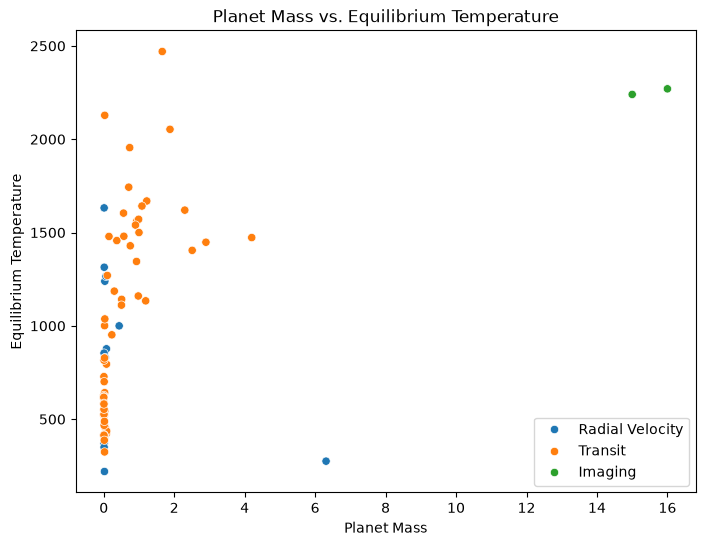

In [38]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df3, x="pl_bmassj", y="pl_eqt", hue="discoverymethod")
plt.title("Planet Mass vs. Equilibrium Temperature")
plt.xlabel("Planet Mass")
plt.ylabel("Equilibrium Temperature")
plt.legend()
plt.show()

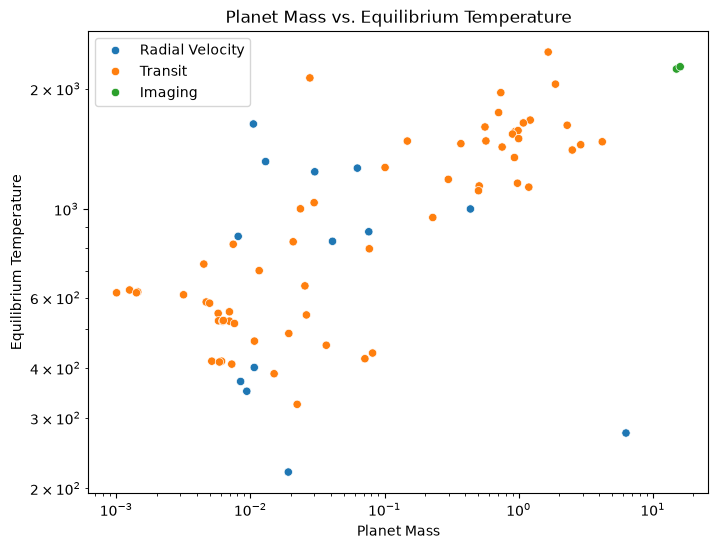

In [47]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df3, x="pl_bmassj", y="pl_eqt", hue="discoverymethod")
plt.xscale("log")
plt.yscale("log")
plt.title("Planet Mass vs. Equilibrium Temperature")
plt.xlabel("Planet Mass")
plt.ylabel("Equilibrium Temperature")
plt.legend()
plt.show()

# Imaging is more likely to find massive planets

In [56]:
df4 = df3[df3["pl_bmassj"] > 5]
print(df4.loc[df4["pl_eqt"].idxmin()])
# eps Ind A b, 597, 275 K, 6.31 Jupiter masses, K5 V (not like the sun G2 V)

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object


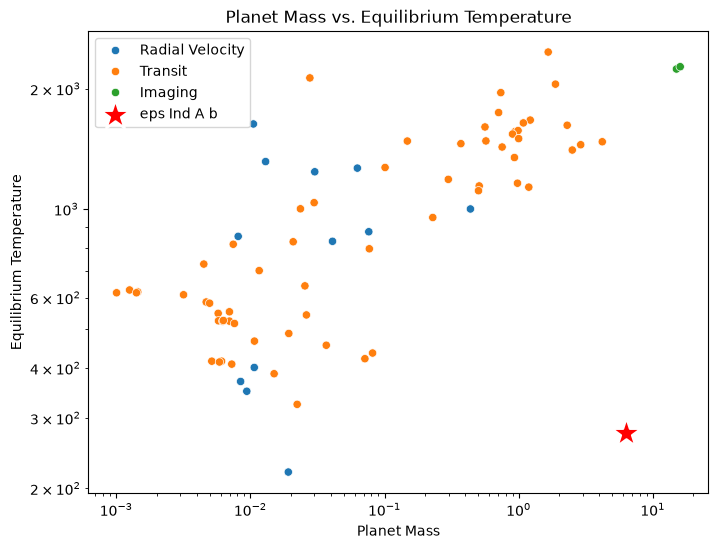

In [62]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df3, x="pl_bmassj", y="pl_eqt", hue="discoverymethod")
sns.scatterplot(data=df3[df3["pl_name"] == "eps Ind A b"], x="pl_bmassj", y="pl_eqt",
            color="red", s=500, marker="*", label="eps Ind A b")
plt.xscale("log")
plt.yscale("log")
plt.title("Planet Mass vs. Equilibrium Temperature")
plt.xlabel("Planet Mass")
plt.ylabel("Equilibrium Temperature")
plt.legend()
plt.show()

1) A temperate super-Jupiter imaged with JWST in the mid-infrared
2) The planet eps Ind A b goes against previous temperature vs. mass trends observed by astronomers. It is bright and cold compared to other planets, and it is probably the only one of its kind in the system.
3) Yes! I found the same planet
4) It is an outlier in the trend of more massive planets having higher equilibrium temperatures
5) Both the mass and equilibrium temperatures match